# Exploratory Data Analysis (EDA)

Now that the data is validated, I want to explore it visually and understand **why customers churn**.

I'll go through:
1. Overall churn rate
2. Churn by subscription plan and billing cycle
3. Churn by region and acquisition channel
4. How usage patterns differ between active vs churned customers
5. Impact of payment failures on churn
6. How support experience affects churn
7. Top stated reasons for cancellation
8. Correlation between features

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.show()

## Load Data

In [33]:
customers = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\customers.csv'
)
subscriptions = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\subscriptions.csv'
)
usage = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\usage.csv'
)
payments = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\payments.csv'
)
support_tickets = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\support_tickets.csv'
)
churn = pd.read_csv(
    r'C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\raw\churn.csv'
)

# Convert date columns
customers['signup_date']        = pd.to_datetime(customers['signup_date'])
subscriptions['start_date']     = pd.to_datetime(subscriptions['start_date'])
subscriptions['end_date']       = pd.to_datetime(subscriptions['end_date'])
churn['churn_date']             = pd.to_datetime(churn['churn_date'])

print('Data loaded.')

Data loaded.


## 1. What is the Overall Churn Rate?

The first thing I want to know is: **how many customers actually left?**

Total Customers  : 20,000
Churned          : 6,603  (33.0%)
Active           : 13,397  (67.0%)


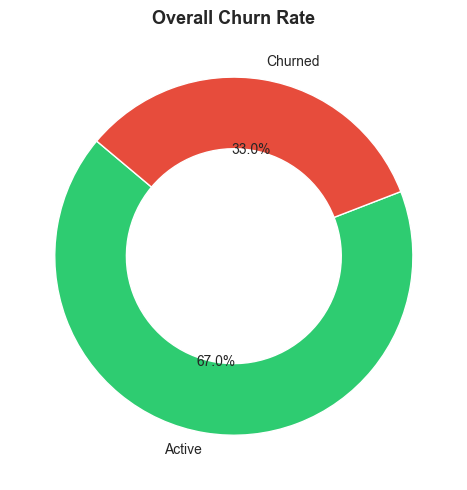

In [31]:
total      = len(churn)
churned    = churn['churn_flag'].sum()
active     = total - churned
churn_rate = churned / total * 100

print(f'Total Customers  : {total:,}')
print(f'Churned          : {churned:,}  ({churn_rate:.1f}%)')
print(f'Active           : {active:,}  ({100 - churn_rate:.1f}%)')

plt.figure(figsize=(5, 5))
plt.pie([active, churned], labels=['Active', 'Churned'], autopct='%1.1f%%',
        colors=['#2ecc71', '#e74c3c'], startangle=140,
        wedgeprops={'edgecolor': 'white', 'width': 0.4})
plt.title('Overall Churn Rate', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

> **1 in every 3 customers churned.** This is quite high and needs investigation.

## 2. Churn by Subscription Plan & Billing Cycle

Does the plan type or how often someone is billed affect whether they leave?

In [24]:
# Join subscriptions with churn target
sub_churn = subscriptions.merge(churn[['customer_id', 'churn_flag']], on='customer_id')

# Churn rate by plan
plan_churn = sub_churn.groupby('plan')['churn_flag'].mean().mul(100).round(1).reset_index()
plan_churn.columns = ['Plan', 'Churn Rate (%)']

# Churn rate by billing cycle
cycle_churn = sub_churn.groupby('billing_cycle')['churn_flag'].mean().mul(100).round(1).reset_index()
cycle_churn.columns = ['Billing Cycle', 'Churn Rate (%)']

print(plan_churn.to_string(index=False))
print()
print(cycle_churn.to_string(index=False))

      Plan  Churn Rate (%)
     Basic            35.5
Enterprise            30.2
       Pro            30.0

Billing Cycle  Churn Rate (%)
       Annual            22.6
      Monthly            37.6


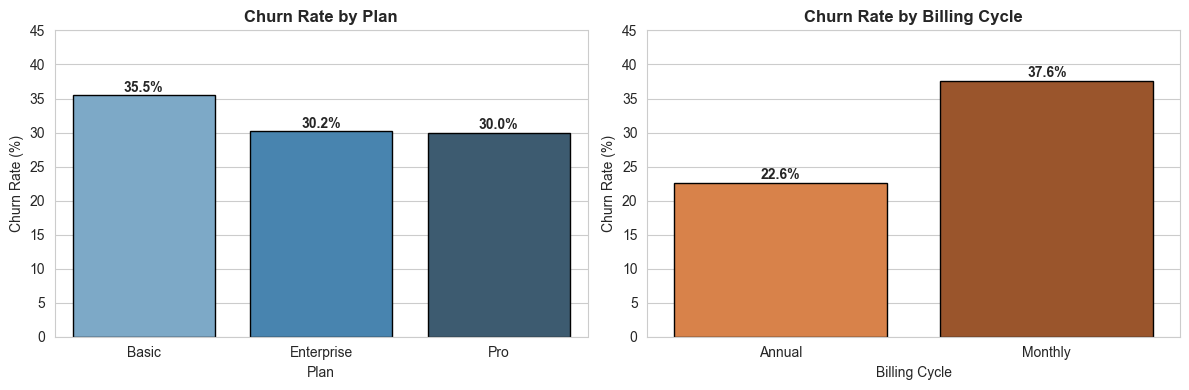

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=plan_churn, x='Plan', y='Churn Rate (%)', ax=axes[0],
            palette='Blues_d', edgecolor='black')
axes[0].set_title('Churn Rate by Plan', fontweight='bold')
axes[0].set_ylim(0, 45)
for p in axes[0].patches:
    axes[0].text(p.get_x() + p.get_width() / 2, p.get_height() + 0.5,
                 f'{p.get_height():.1f}%', ha='center', fontweight='bold')

sns.barplot(data=cycle_churn, x='Billing Cycle', y='Churn Rate (%)', ax=axes[1],
            palette='Oranges_d', edgecolor='black')
axes[1].set_title('Churn Rate by Billing Cycle', fontweight='bold')
axes[1].set_ylim(0, 45)
for p in axes[1].patches:
    axes[1].text(p.get_x() + p.get_width() / 2, p.get_height() + 0.5,
                 f'{p.get_height():.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

> - **Basic plan has the highest churn (35.5%)** — likely price-sensitive customers.
> - **Monthly subscribers churn at 37.6%** vs only **22.6% for Annual** subscribers.
> - Annual contracts create commitment and reduce involuntary churn from billing lapses.

## 3. Churn by Region & Acquisition Channel

Does where a customer comes from influence whether they stay?

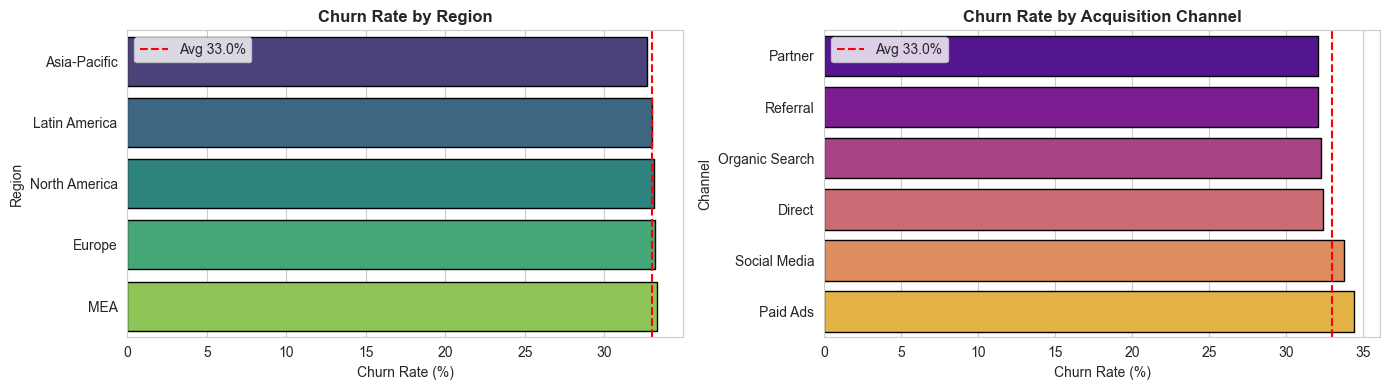

In [26]:
cust_churn = customers.merge(churn[['customer_id', 'churn_flag']], on='customer_id')

region_churn = cust_churn.groupby('region')['churn_flag'].mean().mul(100).round(1).sort_values().reset_index()
region_churn.columns = ['Region', 'Churn Rate (%)']

channel_churn = cust_churn.groupby('acquisition_channel')['churn_flag'].mean().mul(100).round(1).sort_values().reset_index()
channel_churn.columns = ['Channel', 'Churn Rate (%)']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=region_churn, y='Region', x='Churn Rate (%)',
            palette='viridis', ax=axes[0], edgecolor='black')
axes[0].set_title('Churn Rate by Region', fontweight='bold')
axes[0].axvline(churn_rate, color='red', linestyle='--', label=f'Avg {churn_rate:.1f}%')
axes[0].legend()

sns.barplot(data=channel_churn, y='Channel', x='Churn Rate (%)',
            palette='plasma', ax=axes[1], edgecolor='black')
axes[1].set_title('Churn Rate by Acquisition Channel', fontweight='bold')
axes[1].axvline(churn_rate, color='red', linestyle='--', label=f'Avg {churn_rate:.1f}%')
axes[1].legend()

plt.tight_layout()
plt.show()

> Churn rates are fairly consistent across regions (~32-34%), so geography isn't a major driver here.

## 4. Usage Behavior: Active vs Churned Customers

**Hypothesis**: Customers who use the product less frequently will churn sooner.

I'll calculate the **average monthly** usage per customer and compare active vs churned.

In [27]:
# Average monthly usage per customer
avg_usage = usage.groupby('customer_id').agg(
    avg_sessions  = ('sessions_count', 'mean'),
    avg_hours     = ('usage_hours', 'mean'),
    avg_days      = ('active_days', 'mean'),
    avg_features  = ('features_used_count', 'mean')
).reset_index()

# Merge with churn
usage_churn = avg_usage.merge(churn[['customer_id', 'churn_flag']], on='customer_id')
usage_churn['Status'] = usage_churn['churn_flag'].map({0: 'Active', 1: 'Churned'})

# Compare averages
display(usage_churn.groupby('Status')[['avg_sessions', 'avg_hours', 'avg_days', 'avg_features']].mean().round(2))

,avg_sessions,avg_hours,avg_days,avg_features
Status,,,,
Active,28.51,26.17,14.67,5.23
Churned,25.44,22.56,12.61,4.52


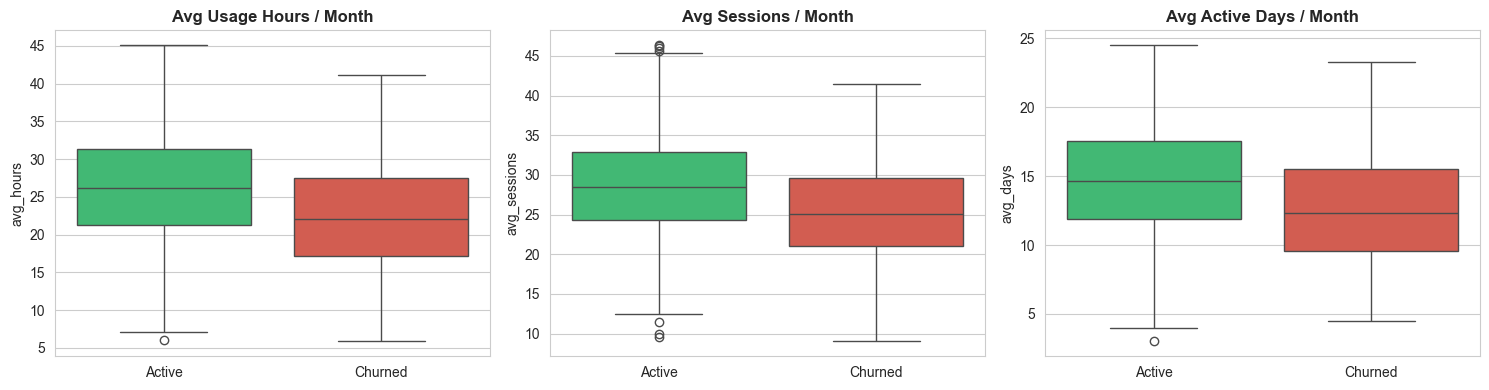

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, label in zip(axes,
    ['avg_hours', 'avg_sessions', 'avg_days'],
    ['Avg Usage Hours / Month', 'Avg Sessions / Month', 'Avg Active Days / Month']):
    sns.boxplot(data=usage_churn, x='Status', y=col,
                palette={'Active': '#2ecc71', 'Churned': '#e74c3c'}, ax=ax)
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

> - Churned customers averaged **22.6 hours/month** vs **26.2 hours/month** for active customers.
> - They were also active **fewer days per month** and used **fewer features**.
> - Drop in usage is an early warning signal — this can be used as a churn predictor in the model.

## 5. Impact of Failed Payments on Churn

Many customers churn not because they want to, but because their card fails and no one follows up.
Let's check how often this happens.

,Group,Count,Churned,Churn_Rate
0,No Failed Payments,8286,1701,20.53
1,Had Failed Payment(s),11714,4902,41.85


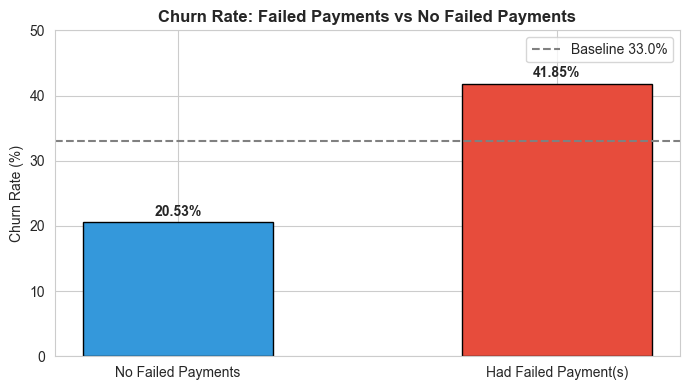

In [29]:
# Which customers had at least one failed payment?
failed_ids = set(payments[payments['payment_status'] == 'Failed']['customer_id'])
churn['had_failed_payment'] = churn['customer_id'].isin(failed_ids).astype(int)

fail_summary = churn.groupby('had_failed_payment')['churn_flag'].agg(
    Count='count',
    Churned='sum',
    Churn_Rate=lambda x: round(x.mean() * 100, 2)
).reset_index()
fail_summary['Group'] = fail_summary['had_failed_payment'].map({0: 'No Failed Payments', 1: 'Had Failed Payment(s)'})

display(fail_summary[['Group', 'Count', 'Churned', 'Churn_Rate']])

plt.figure(figsize=(7, 4))
bars = plt.bar(fail_summary['Group'], fail_summary['Churn_Rate'],
               color=['#3498db', '#e74c3c'], edgecolor='black', width=0.5)
plt.title('Churn Rate: Failed Payments vs No Failed Payments', fontweight='bold')
plt.ylabel('Churn Rate (%)')
plt.ylim(0, 50)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, h + 1, f'{h}%', ha='center', fontweight='bold')
plt.axhline(churn_rate, color='gray', linestyle='--', label=f'Baseline {churn_rate:.1f}%')
plt.legend()
plt.tight_layout()
plt.show()

> - **No failed payments → 20.5% churn**
> - **Had failed payments → 41.8% churn** (more than double!)
> - This is the **single biggest driver of churn** in this dataset.

## 6. Customer Support Quality vs Churn

Does poor support experience push customers to cancel?

In [34]:
# Average support metrics per customer
support_agg = support_tickets.groupby('customer_id').agg(
    num_tickets      = ('ticket_id', 'count'),
    avg_resolution   = ('resolution_time_hours', 'mean'),
    avg_csat         = ('satisfaction_score', 'mean')
).reset_index()

support_churn = support_agg.merge(churn[['customer_id', 'churn_flag']], on='customer_id')
support_churn['Status'] = support_churn['churn_flag'].map({0: 'Active', 1: 'Churned'})

print('Average support metrics by churn status:')
display(support_churn.groupby('Status')[['num_tickets', 'avg_resolution', 'avg_csat']].mean().round(2))

Average support metrics by churn status:


,num_tickets,avg_resolution,avg_csat
Status,,,
Active,2.31,23.53,3.2
Churned,2.57,26.10,2.7


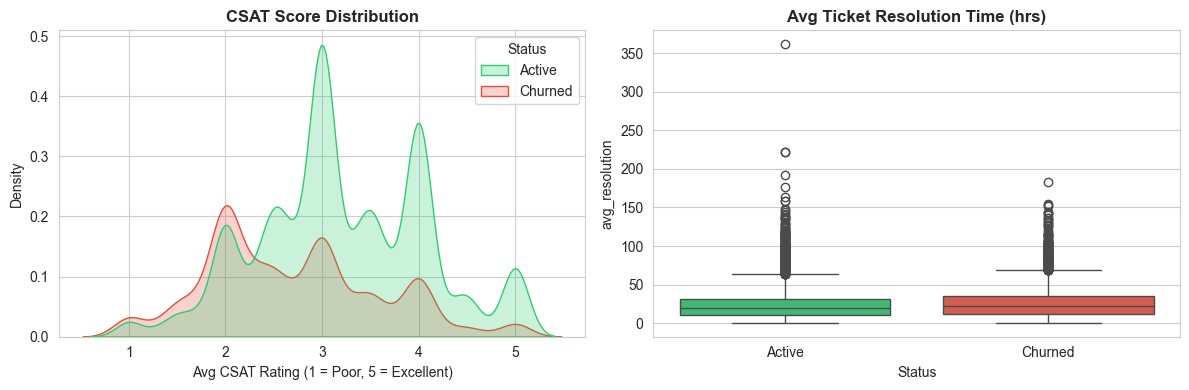

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# CSAT distribution
sns.kdeplot(data=support_churn, x='avg_csat', hue='Status',
            fill=True, palette={'Active': '#2ecc71', 'Churned': '#e74c3c'}, ax=axes[0])
axes[0].set_title('CSAT Score Distribution', fontweight='bold')
axes[0].set_xlabel('Avg CSAT Rating (1 = Poor, 5 = Excellent)')

# Resolution time
sns.boxplot(data=support_churn, x='Status', y='avg_resolution',
            palette={'Active': '#2ecc71', 'Churned': '#e74c3c'}, ax=axes[1])
axes[1].set_title('Avg Ticket Resolution Time (hrs)', fontweight='bold')

plt.tight_layout()
plt.show()

> - Churned customers gave average CSAT of **2.70** vs **3.20** for active customers.
> - Churned customers also waited **longer** for issue resolution (26 hrs vs 23.5 hrs).
> - Customers who had a bad support experience are more likely to leave.

## 7. What Reasons Do Churned Customers Give?

The `churn_reason` column tells us the primary reason a customer cancelled.

,Count,Pct (%)
churn_reason,,
Payment Failure,3578,54.2
Poor Customer Support,1180,17.9
High Price,631,9.6
Competitor Switch,556,8.4
Missing Features,391,5.9
Business Closure,264,4.0
Product Unused,3,0.0


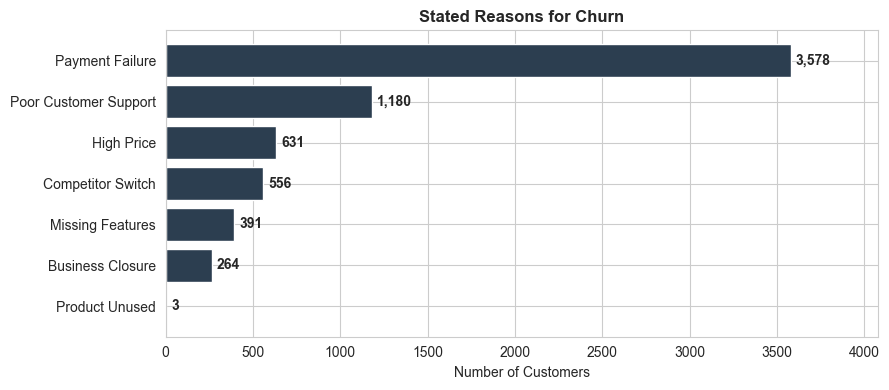

In [36]:
churned_only = churn[churn['churn_flag'] == 1]

reason_counts = churned_only['churn_reason'].value_counts()
reason_pct    = (reason_counts / len(churned_only) * 100).round(1)

reason_df = pd.DataFrame({'Count': reason_counts, 'Pct (%)': reason_pct})
display(reason_df)

plt.figure(figsize=(9, 4))
bars = plt.barh(reason_counts.index[::-1], reason_counts.values[::-1],
                color='#2c3e50', edgecolor='white')
plt.title('Stated Reasons for Churn', fontsize=12, fontweight='bold')
plt.xlabel('Number of Customers')
for bar in bars:
    plt.text(bar.get_width() + 30, bar.get_y() + bar.get_height() / 2,
             f'{bar.get_width():,}', va='center', fontweight='bold')
plt.xlim(0, reason_counts.max() + 500)
plt.tight_layout()
plt.show()

> - **Payment Failure** is #1 by far — 54% of all churns.
> - **Poor Customer Support** is #2 at 18%.
> - Price and competitors together account for another ~18%.
> - Fixing payment retries alone could cut churn by **half**.

## 8. Correlation Heatmap

Let me combine all customer-level signals and see which ones are most correlated with churn.

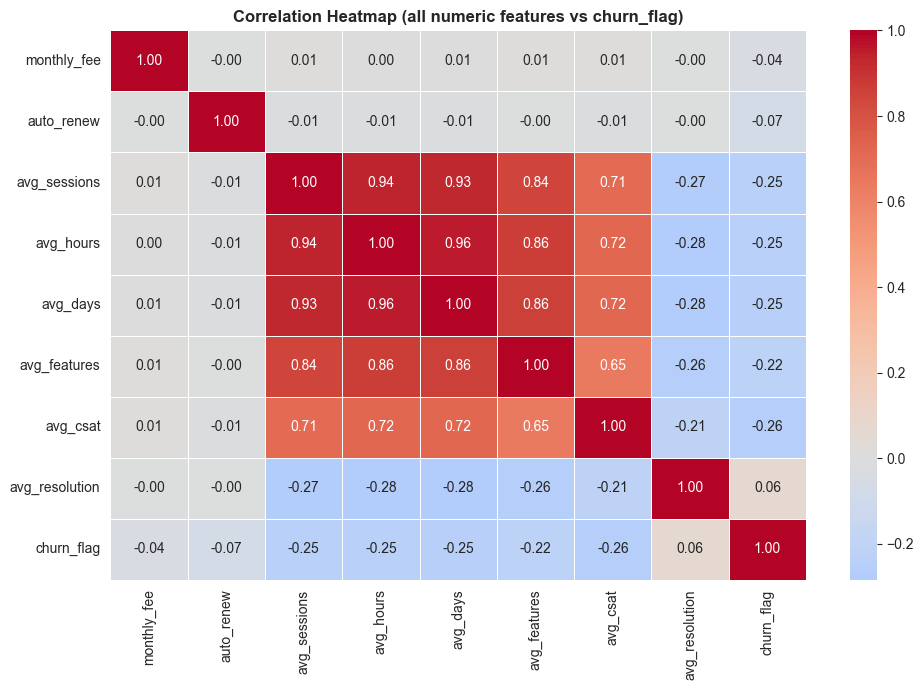

In [39]:
# Build a customer-level table with all key metrics
df = customers[['customer_id']].copy()
df = df.merge(subscriptions[['customer_id', 'monthly_fee', 'auto_renew']], on='customer_id')
df = df.merge(avg_usage[['customer_id', 'avg_sessions', 'avg_hours', 'avg_days', 'avg_features']], on='customer_id')
df = df.merge(support_agg[['customer_id', 'avg_csat', 'avg_resolution']], on='customer_id', how='left')
df = df.merge(churn[['customer_id', 'churn_flag']], on='customer_id')

# Correlation with churn_flag
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('Correlation Heatmap (all numeric features vs churn_flag)', fontweight='bold')
plt.tight_layout()
plt.show()

## Summary of EDA Findings

| What I Looked At | Key Finding |
|---|---|
| Overall churn rate | **33%** — 1 in 3 customers left |
| Billing cycle | Monthly churn (37.6%) >> Annual churn (22.6%) |
| Subscription plan | Basic plan has highest churn at 35.5% |
| Product usage | Churned users had ~14% fewer usage hours |
| Failed payments | Doubles churn rate from 20.5% → 41.8% |
| Support experience | Churned customers rated support 2.70 vs 3.20 |
| Top churn reason | Payment Failure (54% of all cancellations) |

